# Notebook 01 — Eksplorasi Data (Exploratory Spatial Data Analysis)

**Judul Penelitian:** Penentuan Lokasi Rumah Pompa Air Pengendali Banjir Menggunakan Klasterisasi DBSCAN dan K-Means (Studi Kasus: Kota Surabaya)

## Tujuan Notebook Ini
Notebook ini menjalankan **Tahap 1 — Eksplorasi Data** secara *read-only* (tidak mengubah atau menghapus data asli di `data/raw/`):
1. Membaca ketiga dataset utama penelitian dan memeriksa struktur kolom, tipe data, CRS, serta geometri.
2. Memeriksa nilai kosong, distribusi jenis saluran, dan distribusi status rumah pompa.
3. Menguji **validitas topologi 7 poligon rayon pematusan** (`is_valid`, *overlap*, dan konsistensi luas/keliling pada `EPSG:32749`).
4. Melakukan **verifikasi independen Point-in-Polygon (PiP)** dan menganalisis profil serta jarak **65 titik di luar poligon** ke batas rayon terdekat.
5. Membedah profil **130 baris duplikat koordinat** dan duplikat `id_titik` pada data titik saluran.
6. Membuat **visualisasi awal** persebaran spasial dan menyimpan tabel ringkasan ke `outputs/tables/` serta grafik ke `outputs/figures/`.

## 1. Import Library dan Konfigurasi Path Proyek
Kita menggunakan `pathlib.Path` agar path tetap konsisten baik notebook dijalankan dari folder `notebooks/` maupun dari root proyek. Seluruh file keluaran eksplorasi disimpan di `outputs/figures/` dan `outputs/tables/`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.validation import explain_validity
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

# Menentukan root proyek secara otomatis
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TAB_DIR = PROJECT_ROOT / "outputs" / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Pengaturan tampilan Pandas & Matplotlib
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 120

print("Project Root :", PROJECT_ROOT)
print("Versi Library:")
print(f"  pandas     : {pd.__version__}")
print(f"  numpy      : {np.__version__}")
print(f"  geopandas  : {gpd.__version__}")
print(f"  matplotlib : {plt.matplotlib.__version__}")

Project Root : C:\Skripsi\skripsi-rumah-pompa
Versi Library:
  pandas     : 2.3.3
  numpy      : 2.5.5
  geopandas  : 1.2.0
  matplotlib : 3.11.2


## 2. Membaca Ketiga Dataset Utama
Sesuai kesepakatan audit awal:
- Titik saluran drainase: `21467_titik_saluran_clean.geojson`
- Batas 7 rayon pematusan: `7_rayon_pematusan_clean.geojson`
- Lokasi rumah pompa (acuan utama Bab III): `83_rumah_pompa_bab3_clean.geojson`

File `83_rumah_pompa_clean.geojson` dibiarkan utuh di `data/raw/` sebagai arsip.

In [2]:
PATH_SALURAN = RAW_DIR / "21467_titik_saluran_clean.geojson"
PATH_RAYON = RAW_DIR / "7_rayon_pematusan_clean.geojson"
PATH_POMPA = RAW_DIR / "83_rumah_pompa_bab3_clean.geojson"

gdf_saluran = gpd.read_file(PATH_SALURAN)
gdf_rayon = gpd.read_file(PATH_RAYON)
gdf_pompa = gpd.read_file(PATH_POMPA)

def ringkasan_geodataframe(gdf: gpd.GeoDataFrame, nama: str) -> None:
    print("=" * 80)
    print(f"DATASET: {nama}")
    print("=" * 80)
    print(f"Jumlah record   : {len(gdf):,}")
    print(f"Jumlah kolom    : {len(gdf.columns)}")
    print(f"CRS             : {gdf.crs}")
    print(f"Tipe geometri   : {gdf.geom_type.value_counts().to_dict()}")
    print(f"Geometri null   : {int(gdf.geometry.isna().sum())}")
    print(f"Geometri kosong : {int(gdf.geometry.is_empty.sum())}")
    print(f"Total bounds    : {np.round(gdf.total_bounds, 6)}  (minx, miny, maxx, maxy)")
    print("\nStruktur Kolom & Nilai Kosong:")
    info_df = pd.DataFrame({
        "dtype": gdf.dtypes.astype(str),
        "non_null": gdf.notna().sum(),
        "null": gdf.isna().sum(),
        "nunique": [gdf[c].nunique(dropna=True) if c != "geometry" else gdf.geometry.nunique() for c in gdf.columns]
    })
    display(info_df)

ringkasan_geodataframe(gdf_saluran, "Titik Inventarisasi Saluran Drainase")
ringkasan_geodataframe(gdf_rayon, "Batas 7 Rayon Pematusan")
ringkasan_geodataframe(gdf_pompa, "Lokasi Rumah Pompa (Acuan Bab III)")

DATASET: Titik Inventarisasi Saluran Drainase
Jumlah record   : 21,467
Jumlah kolom    : 13
CRS             : EPSG:4326
Tipe geometri   : {'Point': 21467}
Geometri null   : 0
Geometri kosong : 0
Total bounds    : [112.593601  -7.345973 112.822846  -7.206662]  (minx, miny, maxx, maxy)

Struktur Kolom & Nilai Kosong:


,dtype,non_null,null,nunique
no,int32,21467,0,21467
id_titik,object,21467,0,20979
nama_saluran,object,21467,0,20989
kode_hierarki,object,21467,0,6
hierarki_saluran,object,21467,0,4
longitude,float64,21467,0,19528
latitude,float64,21467,0,19264
utm_x,float64,21467,0,19749
utm_y,float64,21467,0,20145
status_pip,object,21467,0,2


DATASET: Batas 7 Rayon Pematusan
Jumlah record   : 7
Jumlah kolom    : 10
CRS             : EPSG:4326
Tipe geometri   : {'Polygon': 7}
Geometri null   : 0
Geometri kosong : 0
Total bounds    : [112.591211  -7.358037 112.846573  -7.192732]  (minx, miny, maxx, maxy)

Struktur Kolom & Nilai Kosong:


,dtype,non_null,null,nunique
no,int32,7,0,7
id_rayon,object,7,0,7
name,object,7,0,7
nama_rayon,object,7,0,7
cakupan_wilayah,object,7,0,7
jumlah_verteks,int32,7,0,7
luas_km2,float64,7,0,7
keliling_km,float64,7,0,7
warna_qgis,object,7,0,7
geometry,geometry,7,0,7


DATASET: Lokasi Rumah Pompa (Acuan Bab III)
Jumlah record   : 83
Jumlah kolom    : 11
CRS             : EPSG:4326
Tipe geometri   : {'Point': 83}
Geometri null   : 0
Geometri kosong : 0
Total bounds    : [112.600212  -7.347834 112.823274  -7.206279]  (minx, miny, maxx, maxy)

Struktur Kolom & Nilai Kosong:


,dtype,non_null,null,nunique
no,int32,83,0,83
id_pompa,object,83,0,83
name,object,83,0,82
nama_stasiun_pompa,object,83,0,82
rayon_pematusan,object,83,0,7
longitude,float64,83,0,81
latitude,float64,83,0,82
utm_x,float64,83,0,82
utm_y,float64,83,0,82
status_fasilitas,object,83,0,2


## 3. Distribusi Atribut Kunci: Jenis Saluran & Status Rumah Pompa
Kita memeriksa:
1. Perbandingan kolom `kode_hierarki` dan `hierarki_saluran` pada 21.467 titik saluran (untuk melihat 3 entri typo kode).
2. Distribusi 83 rumah pompa berdasarkan `status_fasilitas` (71 Operasional Aktif vs 12 Pengembangan Baru) dan sebarannya per rayon, serta mencatat duplikat `P.A Bozem Moro Krembangan I`.

In [3]:
print("--- Distribusi hierarki_saluran vs kode_hierarki ---")
display(pd.crosstab(gdf_saluran["hierarki_saluran"], gdf_saluran["kode_hierarki"], margins=True))

print("\n--- 3 Baris dengan typo kode_hierarki ---")
display(gdf_saluran.loc[
    ~gdf_saluran["kode_hierarki"].isin(["SP", "SS", "ST", "SL"]),
    ["no", "id_titik", "nama_saluran", "kode_hierarki", "hierarki_saluran", "rayon_pip"]
])

print("\n--- Distribusi 83 Rumah Pompa per Rayon x Status Fasilitas ---")
display(pd.crosstab(gdf_pompa["rayon_pematusan"], gdf_pompa["status_fasilitas"], margins=True))

print("\n--- Cek Duplikat Koordinat / Nama pada Data Rumah Pompa ---")
dup_pompa = gdf_pompa[gdf_pompa.duplicated(subset=["longitude", "latitude"], keep=False)]
display(dup_pompa[["no", "id_pompa", "name", "rayon_pematusan", "longitude", "latitude", "status_fasilitas"]])
print(f"Total rumah pompa Operasional Aktif: {(gdf_pompa['status_fasilitas'] == 'Operasional Aktif').sum()} entri "
      f"({gdf_pompa.loc[gdf_pompa['status_fasilitas'] == 'Operasional Aktif', ['longitude', 'latitude']].drop_duplicates().shape[0]} koordinat unik)")

--- Distribusi hierarki_saluran vs kode_hierarki ---


kode_hierarki,SL,SP,SS,ST,Sa,Sl,All
hierarki_saluran,,,,,,,
Saluran Lokal (SL),18657,0,0,0,2,1,18660
Saluran Primer (SP),0,75,0,0,0,0,75
Saluran Sekunder (SS),0,0,400,0,0,0,400
Saluran Tersier (ST),0,0,0,2332,0,0,2332
All,18657,75,400,2332,2,1,21467



--- 3 Baris dengan typo kode_hierarki ---


,no,id_titik,nama_saluran,kode_hierarki,hierarki_saluran,rayon_pip
10965,10966,Sa-10966,SL - 8755 - S L. Semolo Waru Selatan IX - Timur,Sa,Saluran Lokal (SL),Rayon Rungkut
10966,10967,Sa-10967,SL - 8756 - S L. Semolo Waru Selatan VIII - Utara,Sa,Saluran Lokal (SL),Rayon Rungkut
11080,11081,Sl-08408,Sl-08408 - S L. 2,Sl,Saluran Lokal (SL),Rayon Rungkut



--- Distribusi 83 Rumah Pompa per Rayon x Status Fasilitas ---


status_fasilitas,Operasional Aktif,Pengembangan Baru,All
rayon_pematusan,,,
Rayon Benowo,2,0,2
Rayon Genteng,14,1,15
Rayon Gubeng,19,3,22
Rayon Jambangan,11,6,17
Rayon Rungkut,15,1,16
Rayon Tandes,5,1,6
Rayon Wiyung,5,0,5
All,71,12,83



--- Cek Duplikat Koordinat / Nama pada Data Rumah Pompa ---


,no,id_pompa,name,rayon_pematusan,longitude,latitude,status_fasilitas
73,74,PMP-013,P.A Bozem Moro Krembangan I,Rayon Tandes,112.70883,-7.223307,Operasional Aktif
74,75,PMP-014,P.A Bozem Moro Krembangan I,Rayon Tandes,112.70883,-7.223307,Operasional Aktif


Total rumah pompa Operasional Aktif: 71 entri (70 koordinat unik)


## 4. Uji Validitas Topologi 7 Poligon Rayon Pematusan
Sebelum melakukan operasi spasial Point-in-Polygon (PiP), kita **wajib** memastikan poligon batas 7 rayon valid secara geometris:
- `is_valid`: mendeteksi *self-intersection*, cincin tidak tertutup, atau anomali geometri lain.
- Proyeksi ke **UTM Zona 49S (`EPSG:32749`)** agar perhitungan luas (m² → km²), keliling (m → km), dan *overlap* antar-rayon akurat dalam satuan metrik.
- Uji pasangan poligon (*pairwise intersection*): memastikan tidak ada tumpang tindih (*overlap*) antar-rayon yang bisa membuat satu titik saluran masuk ke dua rayon sekaligus.

In [4]:
# Proyeksi sementara (copy) ke EPSG:32749 (UTM Zona 49S) dalam satuan meter
CRS_UTM = "EPSG:32749"
gdf_rayon_utm = gdf_rayon.to_crs(CRS_UTM).copy()
gdf_saluran_utm = gdf_saluran.to_crs(CRS_UTM).copy()
gdf_pompa_utm = gdf_pompa.to_crs(CRS_UTM).copy()

# 4a. Validitas geometri per poligon
topo_rows = []
for idx, row in gdf_rayon_utm.iterrows():
    geom_wgs = gdf_rayon.loc[idx, "geometry"]
    geom_utm = row["geometry"]
    luas_hitung_km2 = geom_utm.area / 1e6
    keliling_hitung_km = geom_utm.length / 1e3
    topo_rows.append({
        "id_rayon": row["id_rayon"],
        "nama_rayon": row["nama_rayon"],
        "valid_wgs84": geom_wgs.is_valid,
        "valid_utm49s": geom_utm.is_valid,
        "alasan_validitas": explain_validity(geom_utm),
        "is_simple": geom_utm.is_simple,
        "luas_atribut_km2": row["luas_km2"],
        "luas_utm49s_km2": round(luas_hitung_km2, 4),
        "selisih_luas_km2": round(luas_hitung_km2 - row["luas_km2"], 4),
        "keliling_atribut_km": row["keliling_km"],
        "keliling_utm49s_km": round(keliling_hitung_km, 4),
    })

df_topo = pd.DataFrame(topo_rows)
print("--- Validitas Geometri & Perbandingan Luas/Keliling 7 Rayon ---")
display(df_topo)
print(f"Total luas (atribut): {df_topo['luas_atribut_km2'].sum():.2f} km2 | "
      f"Total luas (UTM 49S): {df_topo['luas_utm49s_km2'].sum():.2f} km2")

# 4b. Cek overlap dan sentuhan antar-pasangan rayon
overlap_rows = []
n_rayon = len(gdf_rayon_utm)
for i in range(n_rayon):
    for j in range(i + 1, n_rayon):
        r1 = gdf_rayon_utm.iloc[i]
        r2 = gdf_rayon_utm.iloc[j]
        inter = r1.geometry.intersection(r2.geometry)
        area_m2 = inter.area
        length_m = inter.length
        if area_m2 > 0 or length_m > 0:
            overlap_rows.append({
                "rayon_1": r1["nama_rayon"],
                "rayon_2": r2["nama_rayon"],
                "tipe_irisan": inter.geom_type,
                "luas_overlap_m2": round(area_m2, 4),
                "panjang_batas_bersama_m": round(length_m, 2),
                "overlaps_flag": r1.geometry.overlaps(r2.geometry),
                "touches_flag": r1.geometry.touches(r2.geometry),
            })

df_overlap = pd.DataFrame(overlap_rows)
print("\n--- Uji Irisan / Overlap Antar-Rayon (EPSG:32749) ---")
if len(df_overlap) == 0:
    print("Tidak ada poligon yang bersentuhan atau bertumpang tindih.")
else:
    display(df_overlap.sort_values("luas_overlap_m2", ascending=False))
    n_true_overlap = int((df_overlap["luas_overlap_m2"] > 1e-3).sum())
    print(f"Jumlah pasangan rayon dengan luas overlap > 0.001 m2: {n_true_overlap}")

# Cek apakah gabungan 7 poligon menyisakan lubang (gap/sliver) di dalam kota
union_rayon = gdf_rayon_utm.geometry.union_all()
n_holes = sum(len(p.interiors) for p in (union_rayon.geoms if union_rayon.geom_type == "MultiPolygon" else [union_rayon]))
print(f"Tipe geometri union 7 rayon: {union_rayon.geom_type} | Jumlah lubang internal (gap/sliver): {n_holes}")
if n_holes > 0:
    from shapely.geometry import Polygon
    polys = union_rayon.geoms if union_rayon.geom_type == "MultiPolygon" else [union_rayon]
    hole_areas = [round(Polygon(ring).area, 2) for p in polys for ring in p.interiors]
    print(f"Luas masing-masing gap/sliver internal (m2): {sorted(hole_areas, reverse=True)[:10]} (total {len(hole_areas)} lubang, total luas={sum(hole_areas):.2f} m2)")

--- Validitas Geometri & Perbandingan Luas/Keliling 7 Rayon ---

,id_rayon,nama_rayon,valid_wgs84,valid_utm49s,alasan_validitas,is_simple,luas_atribut_km2,luas_utm49s_km2,selisih_luas_km2,keliling_atribut_km,keliling_utm49s_km
0,RYN-01,Rayon Benowo,True,True,Valid Geometry,True,48.64,48.6374,-0.0026,36.85,36.8542
1,RYN-02,Rayon Tandes,True,True,Valid Geometry,True,51.38,51.3821,0.0021,35.88,35.8761
2,RYN-03,Rayon Wiyung,True,True,Valid Geometry,True,55.88,55.8808,0.0008,44.11,44.1069
3,RYN-04,Rayon Jambangan,True,True,Valid Geometry,True,31.25,31.2454,-0.0046,26.13,26.1326
4,RYN-05,Rayon Rungkut,True,True,Valid Geometry,True,56.03,56.0328,0.0028,32.46,32.4554
5,RYN-06,Rayon Genteng,True,True,Valid Geometry,True,27.95,27.9483,-0.0017,31.37,31.3729
6,RYN-07,Rayon Gubeng,True,True,Valid Geometry,True,69.86,69.8609,0.0009,39.30,39.2994


Total luas (atribut): 340.99 km2 | Total luas (UTM 49S): 340.99 km2

--- Uji Irisan / Overlap Antar-Rayon (EPSG:32749) ---


,rayon_1,rayon_2,tipe_irisan,luas_overlap_m2,panjang_batas_bersama_m,overlaps_flag,touches_flag
0,Rayon Benowo,Rayon Tandes,MultiPolygon,2.409862e+06,17373.18,True,False
1,Rayon Benowo,Rayon Wiyung,MultiPolygon,1.082814e+06,5120.62,True,False
2,Rayon Tandes,Rayon Wiyung,MultiPolygon,4.084209e+04,12042.19,True,False
8,Rayon Genteng,Rayon Gubeng,Polygon,3.300959e+04,4646.78,True,False
5,Rayon Wiyung,Rayon Genteng,MultiPolygon,2.860001e+04,1447.27,True,False
4,Rayon Wiyung,Rayon Jambangan,MultiPolygon,1.092281e+04,1340.72,True,False
3,Rayon Tandes,Rayon Genteng,MultiPolygon,9.317243e+03,6636.94,True,False
7,Rayon Rungkut,Rayon Gubeng,MultiPolygon,2.849806e+03,746.64,True,False
6,Rayon Jambangan,Rayon Rungkut,MultiPolygon,4.337109e+02,587.17,True,False


Jumlah pasangan rayon dengan luas overlap > 0.001 m2: 9
Tipe geometri union 7 rayon: Polygon | Jumlah lubang internal (gap/sliver): 53
Luas masing-masing gap/sliver internal (m2): [565272.31, 140415.09, 88414.04, 43836.93, 17028.95, 15275.86, 12159.16, 10675.74, 6570.95, 5478.05] (total 53 lubang, total luas=929968.70 m2)


## 5. Verifikasi Independen Point-in-Polygon & Profil 65 Titik di Luar Poligon
Di dataset raw sudah terdapat kolom `status_pip`, `rayon_pip`, dan `rayon_terdekat`. Namun sesuai prinsip metodologi, kita **tidak boleh mempercayainya begitu saja** tanpa verifikasi independen:
1. Kita jalankan `gpd.sjoin` pada CRS `EPSG:32749` dengan predikat `within` (murni di dalam poligon) dan `intersects` (di dalam ATAU tepat di garis batas poligon) untuk mengetahui apakah ada titik yang tepat menempel di garis batas (*boundary/touches*).
2. Kita cek apakah ada titik yang cocok ke lebih dari 1 rayon (indikasi *overlap* batas).
3. Untuk seluruh titik yang berada di luar poligon, kita hitung **jarak lurus (Euclidean, dalam meter)** ke batas poligon rayon terdekat dan rayon kedua terdekat.

In [5]:
# 5a. Spatial join independen (EPSG:32749)
join_within = gpd.sjoin(
    gdf_saluran_utm[["no", "id_titik", "nama_saluran", "hierarki_saluran", "status_pip", "rayon_pip", "rayon_terdekat", "geometry"]],
    gdf_rayon_utm[["id_rayon", "nama_rayon", "geometry"]],
    how="left",
    predicate="within"
)
join_intersects = gpd.sjoin(
    gdf_saluran_utm[["no", "geometry"]],
    gdf_rayon_utm[["nama_rayon", "geometry"]],
    how="left",
    predicate="intersects"
)

# Cek potensi multi-match (1 titik masuk ke >1 rayon)
multi_within = join_within[join_within.duplicated("no", keep=False)]
multi_intersects = join_intersects[join_intersects.duplicated("no", keep=False)]
print(f"Titik cocok ke >1 rayon (within)     : {multi_within['no'].nunique()}")
print(f"Titik cocok ke >1 rayon (intersects) : {multi_intersects['no'].nunique()}")

# Klasifikasi status spasial independen
in_within = set(join_within.loc[join_within["nama_rayon"].notna(), "no"])
in_intersects = set(join_intersects.loc[join_intersects["nama_rayon"].notna(), "no"])
on_boundary = in_intersects - in_within
outside_all = set(gdf_saluran_utm["no"]) - in_intersects

print(f"\nHasil Verifikasi Independen (EPSG:32749):")
print(f"  - Di dalam poligon (strictly within) : {len(in_within):,}")
print(f"  - Tepat pada garis batas (touches)   : {len(on_boundary):,}")
print(f"  - Di luar seluruh poligon            : {len(outside_all):,}")
print(f"  - Total                              : {len(in_within) + len(on_boundary) + len(outside_all):,}")

# Bandingkan hasil PiP independen (intersects) dengan kolom rayon_pip bawaan
pip_check = join_intersects.drop_duplicates("no").merge(
    gdf_saluran[["no", "status_pip", "rayon_pip", "rayon_terdekat"]],
    on="no",
    how="left"
)
sama_rayon = (pip_check["nama_rayon"].fillna("NONE") == pip_check["rayon_pip"].fillna("NONE")).sum()
print(f"Kecocokan hasil PiP independen vs kolom 'rayon_pip' bawaan: {sama_rayon:,} / {len(gdf_saluran):,}")

# 5b. Hitung jarak setiap titik di luar poligon ke seluruh 7 rayon (dalam meter)
gdf_outside = gdf_saluran_utm[gdf_saluran_utm["no"].isin(outside_all)].copy()
rayon_geoms = list(zip(gdf_rayon_utm["nama_rayon"], gdf_rayon_utm.geometry))

nearest_records = []
for row in gdf_outside.itertuples():
    dists = sorted([(rname, row.geometry.distance(rgeom)) for rname, rgeom in rayon_geoms], key=lambda x: x[1])
    nearest_records.append({
        "no": row.no,
        "id_titik": row.id_titik,
        "nama_saluran": row.nama_saluran,
        "hierarki_saluran": row.hierarki_saluran,
        "longitude": row.longitude,
        "latitude": row.latitude,
        "rayon_terdekat_bawaan": row.rayon_terdekat,
        "rayon_terdekat_hitung": dists[0][0],
        "jarak_terdekat_m": round(dists[0][1], 2),
        "rayon_kedua": dists[1][0],
        "jarak_kedua_m": round(dists[1][1], 2),
        "selisih_jarak_1_2_m": round(dists[1][1] - dists[0][1], 2),
    })

df_outside = pd.DataFrame(nearest_records).sort_values("jarak_terdekat_m", ascending=False).reset_index(drop=True)

print("\n--- Statistik Jarak Titik Luar Poligon ke Batas Rayon Terdekat (meter) ---")
display(df_outside["jarak_terdekat_m"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).to_frame().T)

# Binning jarak untuk memahami apakah menempel batas atau jauh di luar
bins = [0, 5, 10, 25, 50, 100, 250, 500, np.inf]
labels = ["0-5 m", "5-10 m", "10-25 m", "25-50 m", "50-100 m", "100-250 m", "250-500 m", ">500 m"]
df_outside["kategori_jarak"] = pd.cut(df_outside["jarak_terdekat_m"], bins=bins, labels=labels, right=True)

print("\n--- Sebaran Titik Luar Poligon: Rayon Terdekat x Kategori Jarak ---")
display(pd.crosstab(df_outside["rayon_terdekat_hitung"], df_outside["kategori_jarak"], margins=True))

print("\n--- Kecocokan rayon_terdekat bawaan vs perhitungan independen ---")
print("Cocok:", int((df_outside["rayon_terdekat_bawaan"] == df_outside["rayon_terdekat_hitung"]).sum()), "/", len(df_outside))

print("\n--- 15 Titik Luar Poligon Terjauh dari Batas Rayon ---")
display(df_outside.head(15)[[
    "no", "id_titik", "nama_saluran", "hierarki_saluran",
    "rayon_terdekat_hitung", "jarak_terdekat_m", "rayon_kedua", "jarak_kedua_m"
]])

# Simpan tabel profil titik luar poligon
out_csv_outside = TAB_DIR / "01_eda_titik_luar_poligon.csv"
df_outside.to_csv(out_csv_outside, index=False)
print(f"Tabel disimpan ke: {out_csv_outside}")

Titik cocok ke >1 rayon (within)     : 87
Titik cocok ke >1 rayon (intersects) : 87

Hasil Verifikasi Independen (EPSG:32749):
  - Di dalam poligon (strictly within) : 21,402
  - Tepat pada garis batas (touches)   : 0
  - Di luar seluruh poligon            : 65
  - Total                              : 21,467
Kecocokan hasil PiP independen vs kolom 'rayon_pip' bawaan: 21,389 / 21,467

--- Statistik Jarak Titik Luar Poligon ke Batas Rayon Terdekat (meter) ---


,count,mean,std,min,25%,50%,75%,90%,95%,max
jarak_terdekat_m,65.0,88.435231,65.702096,0.27,12.19,106.88,130.56,171.748,201.59,226.51



--- Sebaran Titik Luar Poligon: Rayon Terdekat x Kategori Jarak ---


kategori_jarak,0-5 m,5-10 m,10-25 m,25-50 m,50-100 m,100-250 m,All
rayon_terdekat_hitung,,,,,,,
Rayon Genteng,3,0,0,0,0,0,3
Rayon Gubeng,4,2,2,0,0,0,8
Rayon Jambangan,3,0,1,1,12,33,50
Rayon Tandes,2,2,0,0,0,0,4
All,12,4,3,1,12,33,65



--- Kecocokan rayon_terdekat bawaan vs perhitungan independen ---
Cocok: 65 / 65

--- 15 Titik Luar Poligon Terjauh dari Batas Rayon ---


,no,id_titik,nama_saluran,hierarki_saluran,rayon_terdekat_hitung,jarak_terdekat_m,rayon_kedua,jarak_kedua_m
0,799,ST-473,ST-473 - S T. Simowau Indah,Saluran Tersier (ST),Rayon Jambangan,226.51,Rayon Wiyung,443.70
1,7532,SL-5801,SL-5801 - S L. Gg. Melon,Saluran Lokal (SL),Rayon Jambangan,214.96,Rayon Wiyung,422.69
2,7530,SL-5799,SL-5799 - S L. Tertutup Gg. Apel,Saluran Lokal (SL),Rayon Jambangan,203.97,Rayon Wiyung,339.69
3,797,ST-471,ST-471 - S T. SImowau Baru - Selatan,Saluran Tersier (ST),Rayon Jambangan,202.35,Rayon Wiyung,392.49
4,800,ST-474,ST-474 - S T. Simowau Gg. Bina,Saluran Tersier (ST),Rayon Jambangan,198.55,Rayon Wiyung,227.44
5,7531,SL-5800,SL-5800 - S L. Tertutup Simowau Baru Gg. Kurma,Saluran Lokal (SL),Rayon Jambangan,190.99,Rayon Wiyung,336.50
6,802,ST-476,ST-476 - S T. Simowau Indah,Saluran Tersier (ST),Rayon Jambangan,173.66,Rayon Wiyung,547.42
7,7527,SL-5796,SL-5796 - S L. Gg. Delima,Saluran Lokal (SL),Rayon Jambangan,168.88,Rayon Wiyung,334.68
8,7528,SL-5797,SL-5797 - S L. Simowau Gg. Mulya (Timur) - Se...,Saluran Lokal (SL),Rayon Jambangan,157.50,Rayon Wiyung,270.47
9,7529,SL-5798,SL-5798 - S L. Simowau Gg. Mulya (Timur) - Utara,Saluran Lokal (SL),Rayon Jambangan,154.52,Rayon Wiyung,273.99


Tabel disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\tables\01_eda_titik_luar_poligon.csv


## 6. Profil 130 Baris Duplikat Koordinat & Duplikat `id_titik` Titik Saluran
Kita membedah dua fenomena duplikasi secara terpisah agar tidak salah ambil keputusan di Tahap 2:
1. **Duplikat koordinat persis `(longitude, latitude)`**:
   - **Tipe A (Identik Penuh)**: Koordinat sama, `id_titik` sama, dan `nama_saluran` sama (indikasi kuat pencatatan ganda).
   - **Tipe B (Koordinat Sama, Saluran Berbeda)**: Koordinat sama, tetapi `id_titik` atau `nama_saluran` berbeda (bisa jadi dua saluran bertemu pada satu titik koordinat yang sama atau pembulatan koordinat).
2. **Duplikat `id_titik` dengan koordinat berbeda**: Satu kode saluran yang memiliki beberapa titik inventarisasi pada posisi berbeda (bukan duplikat spasial).

In [6]:
# 6a. Identifikasi seluruh baris yang memiliki koordinat (longitude, latitude) duplikat
df_sal = gdf_saluran.drop(columns="geometry").copy()
df_sal["easting_utm"] = gdf_saluran_utm.geometry.x
df_sal["northing_utm"] = gdf_saluran_utm.geometry.y

mask_dup_xy = df_sal.duplicated(subset=["longitude", "latitude"], keep=False)
df_dup_xy = df_sal[mask_dup_xy].copy()

# Analisis per kelompok koordinat
grp_rows = []
for (lon, lat), grp in df_dup_xy.groupby(["longitude", "latitude"]):
    n_rows = len(grp)
    n_id = grp["id_titik"].nunique()
    n_nama = grp["nama_saluran"].nunique()
    if n_id == 1 and n_nama == 1:
        tipe = "Tipe A: Identik Penuh (ID & Nama Sama)"
    elif n_id < n_rows or n_nama < n_rows:
        tipe = "Tipe C: Campuran (Sebagian Identik, Sebagian Beda)"
    else:
        tipe = "Tipe B: Koordinat Sama, ID & Nama Berbeda"
    grp_rows.append({
        "longitude": lon,
        "latitude": lat,
        "jumlah_baris": n_rows,
        "baris_berlebih": n_rows - 1,
        "nunique_id_titik": n_id,
        "nunique_nama_saluran": n_nama,
        "rayon_pip": grp["rayon_pip"].fillna("Luar Poligon").iloc[0],
        "hierarki_saluran": ", ".join(sorted(grp["hierarki_saluran"].unique())),
        "tipe_duplikat": tipe,
        "daftar_id": "; ".join(grp["id_titik"].astype(str).tolist()),
    })

df_dup_groups = pd.DataFrame(grp_rows).sort_values(["jumlah_baris", "rayon_pip"], ascending=[False, True]).reset_index(drop=True)

print(f"Total baris terlibat duplikat koordinat : {len(df_dup_xy)} baris")
print(f"Jumlah lokasi (koordinat unik) duplikat : {len(df_dup_groups)} lokasi")
print(f"Jumlah baris berlebih (extra rows)      : {len(df_dup_xy) - len(df_dup_groups)} baris")

print("\n--- Ringkasan Berdasarkan Tipe Duplikat Koordinat ---")
summary_tipe = df_dup_groups.groupby("tipe_duplikat").agg(
    jumlah_lokasi=("jumlah_baris", "count"),
    total_baris=("jumlah_baris", "sum"),
    baris_berlebih=("baris_berlebih", "sum")
)
display(summary_tipe)

print("\n--- Sebaran Duplikat Koordinat per Rayon x Tipe Duplikat (Jumlah Baris Berlebih) ---")
display(pd.pivot_table(
    df_dup_groups,
    index="rayon_pip",
    columns="tipe_duplikat",
    values="baris_berlebih",
    aggfunc="sum",
    fill_value=0,
    margins=True
))

print("\n--- Contoh Kelompok Tipe B (Koordinat Sama, ID & Nama Berbeda) ---")
display(df_dup_groups[df_dup_groups["tipe_duplikat"].str.startswith("Tipe B")].head(10))

# Simpan detail seluruh baris duplikat koordinat
df_dup_xy_export = df_dup_xy.merge(
    df_dup_groups[["longitude", "latitude", "jumlah_baris", "tipe_duplikat"]],
    on=["longitude", "latitude"],
    how="left"
).sort_values(["tipe_duplikat", "rayon_pip", "longitude", "latitude", "no"])

out_csv_dup = TAB_DIR / "01_eda_duplikat_koordinat_saluran.csv"
df_dup_xy_export.to_csv(out_csv_dup, index=False)
print(f"Detail 214 baris duplikat koordinat disimpan ke: {out_csv_dup}")

# 6b. Analisis duplikat id_titik dengan koordinat BERBEDA
dup_id_only = df_sal[df_sal.duplicated("id_titik", keep=False)].copy()
id_spread = []
for id_t, grp in dup_id_only.groupby("id_titik"):
    xs = grp["easting_utm"].values
    ys = grp["northing_utm"].values
    max_dist = float(np.sqrt(((xs[:, None] - xs[None, :]) ** 2 + (ys[:, None] - ys[None, :]) ** 2).max()))
    id_spread.append({
        "id_titik": id_t,
        "jumlah_baris": len(grp),
        "nunique_xy": grp[["longitude", "latitude"]].drop_duplicates().shape[0],
        "jarak_maks_antar_titik_m": round(max_dist, 2),
        "rayon_pip": grp["rayon_pip"].fillna("Luar Poligon").iloc[0],
    })
df_id_spread = pd.DataFrame(id_spread)
print("\n--- Profil 410 id_titik yang Muncul > 1 Kali ---")
print(f"  - id_titik dengan jarak maks = 0 m (murni bertumpuk)   : {(df_id_spread['jarak_maks_antar_titik_m'] == 0).sum()}")
print(f"  - id_titik dengan jarak maks > 0 m (posisi berbeda)    : {(df_id_spread['jarak_maks_antar_titik_m'] > 0).sum()}")
display(df_id_spread.loc[df_id_spread["jarak_maks_antar_titik_m"] > 0, "jarak_maks_antar_titik_m"].describe().to_frame().T)

Total baris terlibat duplikat koordinat : 214 baris
Jumlah lokasi (koordinat unik) duplikat : 84 lokasi
Jumlah baris berlebih (extra rows)      : 130 baris

--- Ringkasan Berdasarkan Tipe Duplikat Koordinat ---


,jumlah_lokasi,total_baris,baris_berlebih
tipe_duplikat,,,
Tipe A: Identik Penuh (ID & Nama Sama),60,163,103
"Tipe B: Koordinat Sama, ID & Nama Berbeda",24,51,27



--- Sebaran Duplikat Koordinat per Rayon x Tipe Duplikat (Jumlah Baris Berlebih) ---


tipe_duplikat,Tipe A: Identik Penuh (ID & Nama Sama),"Tipe B: Koordinat Sama, ID & Nama Berbeda",All
rayon_pip,,,
Rayon Genteng,8,0,8
Rayon Gubeng,92,23,115
Rayon Jambangan,0,1,1
Rayon Tandes,3,3,6
All,103,27,130



--- Contoh Kelompok Tipe B (Koordinat Sama, ID & Nama Berbeda) ---


,longitude,latitude,jumlah_baris,baris_berlebih,nunique_id_titik,nunique_nama_saluran,rayon_pip,hierarki_saluran,tipe_duplikat,daftar_id
43,112.770562,-7.227668,3,2,3,3,Rayon Gubeng,Saluran Lokal (SL),"Tipe B: Koordinat Sama, ID & Nama Berbeda",SL-18553; SL-18558; SL-18559
44,112.773449,-7.209735,3,2,3,3,Rayon Gubeng,Saluran Lokal (SL),"Tipe B: Koordinat Sama, ID & Nama Berbeda",SL-18427; SL-18428; SL-18439
45,112.774661,-7.213997,3,2,3,3,Rayon Gubeng,Saluran Lokal (SL),"Tipe B: Koordinat Sama, ID & Nama Berbeda",SL-17191; SL-17280; SL-17282
54,112.748394,-7.218223,2,1,2,2,Rayon Gubeng,Saluran Lokal (SL),"Tipe B: Koordinat Sama, ID & Nama Berbeda",SL-17365; SL-17366
55,112.753964,-7.218636,2,1,2,2,Rayon Gubeng,Saluran Lokal (SL),"Tipe B: Koordinat Sama, ID & Nama Berbeda",SL-19067; SL-19068
56,112.754683,-7.250047,2,1,2,2,Rayon Gubeng,Saluran Lokal (SL),"Tipe B: Koordinat Sama, ID & Nama Berbeda",SL-17710; SL-17711
58,112.758180,-7.218770,2,1,2,2,Rayon Gubeng,Saluran Lokal (SL),"Tipe B: Koordinat Sama, ID & Nama Berbeda",SL-17237; SL-17238
60,112.758236,-7.220627,2,1,2,2,Rayon Gubeng,Saluran Lokal (SL),"Tipe B: Koordinat Sama, ID & Nama Berbeda",SL-17218; SL-17219
63,112.759502,-7.217964,2,1,2,2,Rayon Gubeng,Saluran Lokal (SL),"Tipe B: Koordinat Sama, ID & Nama Berbeda",SL-17159; SL-17160
64,112.760457,-7.233094,2,1,2,2,Rayon Gubeng,Saluran Lokal (SL),"Tipe B: Koordinat Sama, ID & Nama Berbeda",SL-19166; SL-19167


Detail 214 baris duplikat koordinat disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\tables\01_eda_duplikat_koordinat_saluran.csv



--- Profil 410 id_titik yang Muncul > 1 Kali ---
  - id_titik dengan jarak maks = 0 m (murni bertumpuk)   : 58
  - id_titik dengan jarak maks > 0 m (posisi berbeda)    : 352


,count,mean,std,min,25%,50%,75%,max
jarak_maks_antar_titik_m,352.0,495.369716,2243.704797,2.04,44.7975,104.77,225.7675,19291.31


## 7. Visualisasi Awal Persebaran Dataset
Kita membuat 3 gambar eksplorasi dan menyimpannya ke `outputs/figures/`:
1. `01_peta_sebaran_awal.png`: Peta keseluruhan 7 rayon, 21.467 titik saluran (menurut hierarki), 71 rumah pompa aktif, dan 12 rumah pompa pengembangan (layer terpisah).
2. `01_peta_anomali_spasial.png`: Peta khusus 2 panel yang memetakan lokasi 65 titik di luar poligon (dengan warna jarak ke batas rayon) serta lokasi 84 titik duplikat koordinat & duplikat rumah pompa.
3. `01_distribusi_deskriptif.png`: Grafik batang perbandingan jumlah titik saluran & rumah pompa per rayon serta proporsi jenis saluran.

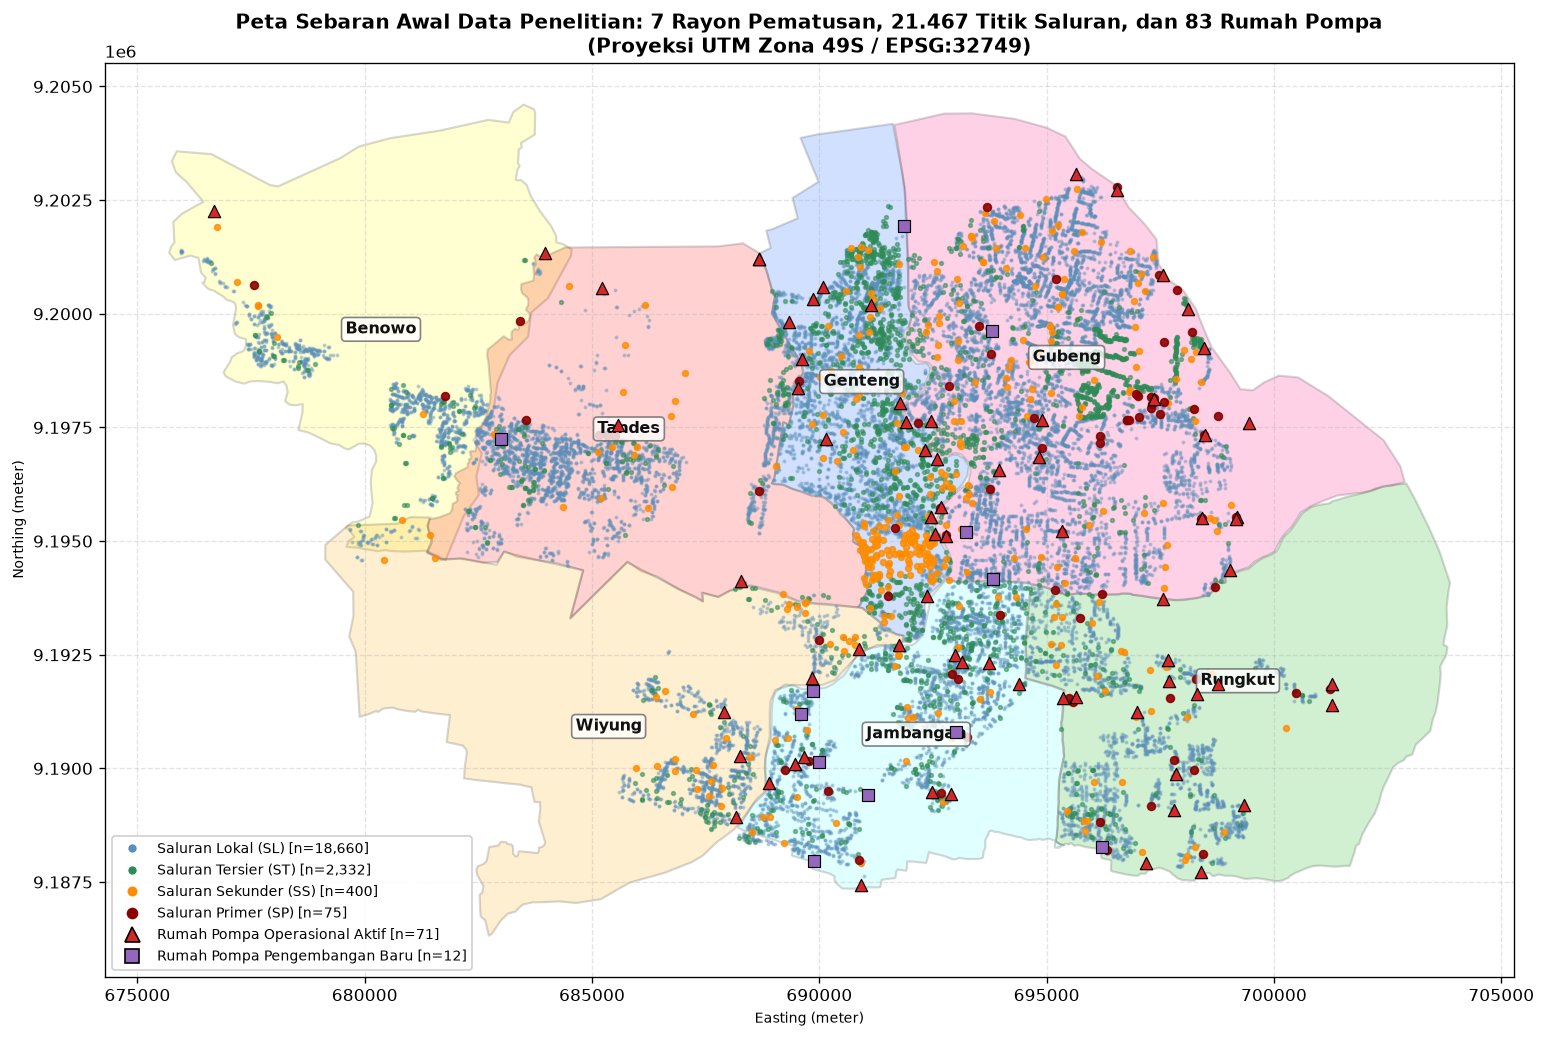

Gambar 1 disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\01_peta_sebaran_awal.png


In [7]:
# --- GAMBAR 1: Peta Sebaran Awal Seluruh Dataset (EPSG:32749 / meter) ---
fig, ax = plt.subplots(figsize=(13, 10))

# Plot 7 poligon rayon dengan warna transparan dari atribut warna_qgis
for _, row in gdf_rayon_utm.iterrows():
    gpd.GeoSeries([row.geometry], crs=CRS_UTM).plot(
        ax=ax,
        facecolor=row["warna_qgis"],
        alpha=0.18,
        edgecolor="#222222",
        linewidth=1.3,
        zorder=1,
    )
    pt_label = row.geometry.representative_point()
    ax.annotate(
        row["nama_rayon"].replace("Rayon ", ""),
        xy=(pt_label.x, pt_label.y),
        ha="center",
        va="center",
        fontsize=9.5,
        fontweight="bold",
        color="#111111",
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#666666", alpha=0.8),
        zorder=6,
    )

# Plot titik saluran berdasarkan hierarki (dari yang terbanyak ke paling utama agar SP terlihat jelas)
hierarki_style = [
    ("Saluran Lokal (SL)", "#5B8FB9", 2.0, 0.35, 2),
    ("Saluran Tersier (ST)", "#2E8B57", 5.0, 0.55, 3),
    ("Saluran Sekunder (SS)", "#FF8C00", 12.0, 0.80, 4),
    ("Saluran Primer (SP)", "#8B0000", 22.0, 0.90, 5),
]
for h_name, color, size, alpha, z in hierarki_style:
    sub = gdf_saluran_utm[gdf_saluran_utm["hierarki_saluran"] == h_name]
    sub.plot(ax=ax, color=color, markersize=size, alpha=alpha, zorder=z)

# Plot rumah pompa (layer terpisah: 71 Aktif vs 12 Pengembangan)
pompa_aktif = gdf_pompa_utm[gdf_pompa_utm["status_fasilitas"] == "Operasional Aktif"]
pompa_kembang = gdf_pompa_utm[gdf_pompa_utm["status_fasilitas"] == "Pengembangan Baru"]

pompa_aktif.plot(ax=ax, color="#D62728", edgecolor="black", marker="^", markersize=55, linewidth=0.7, zorder=7)
pompa_kembang.plot(ax=ax, color="#9467BD", edgecolor="black", marker="s", markersize=50, linewidth=0.7, zorder=8)

legend_handles = [
    Line2D([0], [0], marker="o", color="w", label=f"Saluran Lokal (SL) [n={(gdf_saluran['hierarki_saluran']=='Saluran Lokal (SL)').sum():,}]", markerfacecolor="#5B8FB9", markersize=6),
    Line2D([0], [0], marker="o", color="w", label=f"Saluran Tersier (ST) [n={(gdf_saluran['hierarki_saluran']=='Saluran Tersier (ST)').sum():,}]", markerfacecolor="#2E8B57", markersize=6),
    Line2D([0], [0], marker="o", color="w", label=f"Saluran Sekunder (SS) [n={(gdf_saluran['hierarki_saluran']=='Saluran Sekunder (SS)').sum():,}]", markerfacecolor="#FF8C00", markersize=7),
    Line2D([0], [0], marker="o", color="w", label=f"Saluran Primer (SP) [n={(gdf_saluran['hierarki_saluran']=='Saluran Primer (SP)').sum():,}]", markerfacecolor="#8B0000", markersize=8),
    Line2D([0], [0], marker="^", color="w", label=f"Rumah Pompa Operasional Aktif [n={len(pompa_aktif)}]", markerfacecolor="#D62728", markeredgecolor="black", markersize=9),
    Line2D([0], [0], marker="s", color="w", label=f"Rumah Pompa Pengembangan Baru [n={len(pompa_kembang)}]", markerfacecolor="#9467BD", markeredgecolor="black", markersize=8),
]
ax.legend(handles=legend_handles, loc="lower left", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.5)
ax.set_title("Peta Sebaran Awal Data Penelitian: 7 Rayon Pematusan, 21.467 Titik Saluran, dan 83 Rumah Pompa\n(Proyeksi UTM Zona 49S / EPSG:32749)", fontsize=12, fontweight="bold")
ax.set_xlabel("Easting (meter)")
ax.set_ylabel("Northing (meter)")
ax.grid(True, linestyle="--", alpha=0.35)
ax.set_aspect("equal")

fig_path_1 = FIG_DIR / "01_peta_sebaran_awal.png"
plt.tight_layout()
plt.savefig(fig_path_1, dpi=200, bbox_inches="tight")
plt.show()
print(f"Gambar 1 disimpan ke: {fig_path_1}")

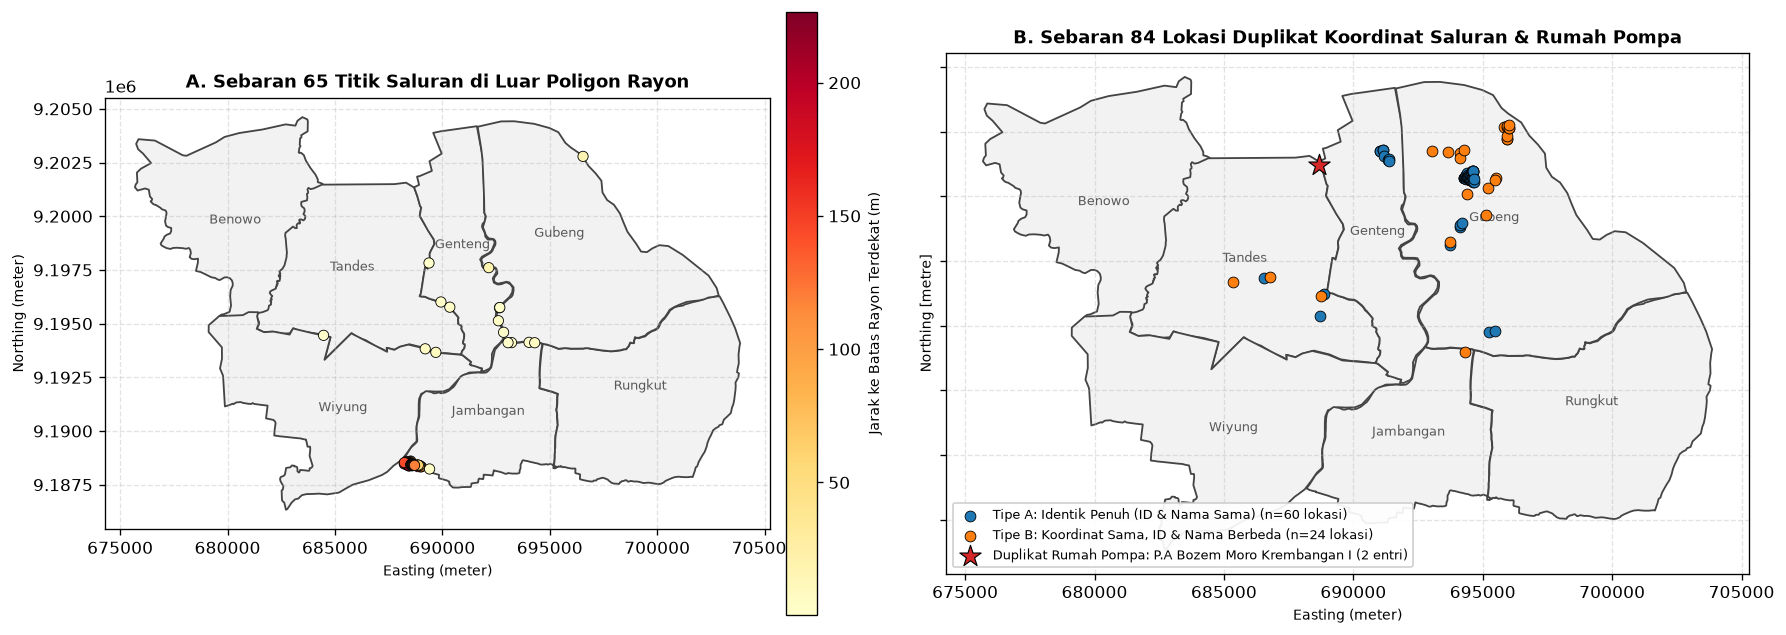

Gambar 2 disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\01_peta_anomali_spasial.png


In [8]:
# --- GAMBAR 2: Peta Khusus Anomali Spasial (65 Titik Luar Poligon & 84 Lokasi Duplikat Koordinat) ---
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharex=True, sharey=True)

# Panel Kiri: 65 Titik Luar Poligon
ax = axes[0]
gdf_rayon_utm.plot(ax=ax, facecolor="#F2F2F2", edgecolor="#444444", linewidth=1.1, zorder=1)
for _, row in gdf_rayon_utm.iterrows():
    pt = row.geometry.representative_point()
    ax.text(pt.x, pt.y, row["nama_rayon"].replace("Rayon ", ""), fontsize=8, ha="center", color="#333333", alpha=0.8)

gdf_outside_plot = gdf_saluran_utm[gdf_saluran_utm["no"].isin(outside_all)].merge(
    df_outside[["no", "jarak_terdekat_m"]], on="no", how="left"
)
sc = ax.scatter(
    gdf_outside_plot.geometry.x,
    gdf_outside_plot.geometry.y,
    c=gdf_outside_plot["jarak_terdekat_m"],
    cmap="YlOrRd",
    s=38,
    edgecolor="black",
    linewidth=0.5,
    zorder=4,
)
cbar = plt.colorbar(sc, ax=ax, shrink=0.75, pad=0.02)
cbar.set_label("Jarak ke Batas Rayon Terdekat (m)", fontsize=8.5)
ax.set_title(f"A. Sebaran {len(gdf_outside_plot)} Titik Saluran di Luar Poligon Rayon", fontsize=11, fontweight="bold")
ax.set_xlabel("Easting (meter)")
ax.set_ylabel("Northing (meter)")
ax.grid(True, linestyle="--", alpha=0.35)

# Panel Kanan: 84 Lokasi Duplikat Koordinat Saluran + 1 Lokasi Duplikat Rumah Pompa
ax = axes[1]
gdf_rayon_utm.plot(ax=ax, facecolor="#F2F2F2", edgecolor="#444444", linewidth=1.1, zorder=1)
for _, row in gdf_rayon_utm.iterrows():
    pt = row.geometry.representative_point()
    ax.text(pt.x, pt.y, row["nama_rayon"].replace("Rayon ", ""), fontsize=8, ha="center", color="#333333", alpha=0.8)

gdf_dup_pts = gpd.GeoDataFrame(
    df_dup_groups,
    geometry=gpd.points_from_xy(df_dup_groups["longitude"], df_dup_groups["latitude"]),
    crs="EPSG:4326"
).to_crs(CRS_UTM)

dup_colors = {
    "Tipe A: Identik Penuh (ID & Nama Sama)": "#1F77B4",
    "Tipe B: Koordinat Sama, ID & Nama Berbeda": "#FF7F0E",
    "Tipe C: Campuran (Sebagian Identik, Sebagian Beda)": "#2CA02C",
}
for tipe, col in dup_colors.items():
    sub = gdf_dup_pts[gdf_dup_pts["tipe_duplikat"] == tipe]
    if len(sub) > 0:
        ax.scatter(sub.geometry.x, sub.geometry.y, color=col, s=42, edgecolor="black", linewidth=0.5, label=f"{tipe} (n={len(sub)} lokasi)", zorder=4)

dup_pompa_utm = gdf_pompa_utm[gdf_pompa_utm.duplicated(subset=["longitude", "latitude"], keep="first")]
ax.scatter(
    dup_pompa_utm.geometry.x,
    dup_pompa_utm.geometry.y,
    color="#D62728",
    marker="*",
    s=180,
    edgecolor="black",
    linewidth=0.7,
    label="Duplikat Rumah Pompa: P.A Bozem Moro Krembangan I (2 entri)",
    zorder=6,
)
ax.legend(loc="lower left", fontsize=7.5, frameon=True, facecolor="white", framealpha=0.92)
ax.set_title(f"B. Sebaran {len(gdf_dup_pts)} Lokasi Duplikat Koordinat Saluran & Rumah Pompa", fontsize=11, fontweight="bold")
ax.set_xlabel("Easting (meter)")
ax.grid(True, linestyle="--", alpha=0.35)

fig_path_2 = FIG_DIR / "01_peta_anomali_spasial.png"
plt.tight_layout()
plt.savefig(fig_path_2, dpi=200, bbox_inches="tight")
plt.show()
print(f"Gambar 2 disimpan ke: {fig_path_2}")

,id_rayon,nama_rayon,luas_km2,titik_dalam_poligon,titik_luar_poligon_terdekat,total_jika_gabung,duplikat_koordinat_berlebih,kepadatan_titik_per_km2,pompa_aktif,pompa_pengembangan,total_pompa
0,RYN-01,Rayon Benowo,48.64,1097,0,1097,0,22.55,2,0,2
1,RYN-02,Rayon Tandes,51.38,2669,4,2673,6,51.95,5,1,6
2,RYN-03,Rayon Wiyung,55.88,1175,0,1175,0,21.03,5,0,5
3,RYN-04,Rayon Jambangan,31.25,2557,50,2607,1,81.82,11,6,17
4,RYN-05,Rayon Rungkut,56.03,2120,0,2120,0,37.84,15,1,16
5,RYN-06,Rayon Genteng,27.95,3726,3,3729,8,133.31,14,1,15
6,RYN-07,Rayon Gubeng,69.86,8058,8,8066,115,115.34,19,3,22


Tabel ringkasan per rayon disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\tables\01_eda_ringkasan_per_rayon.csv


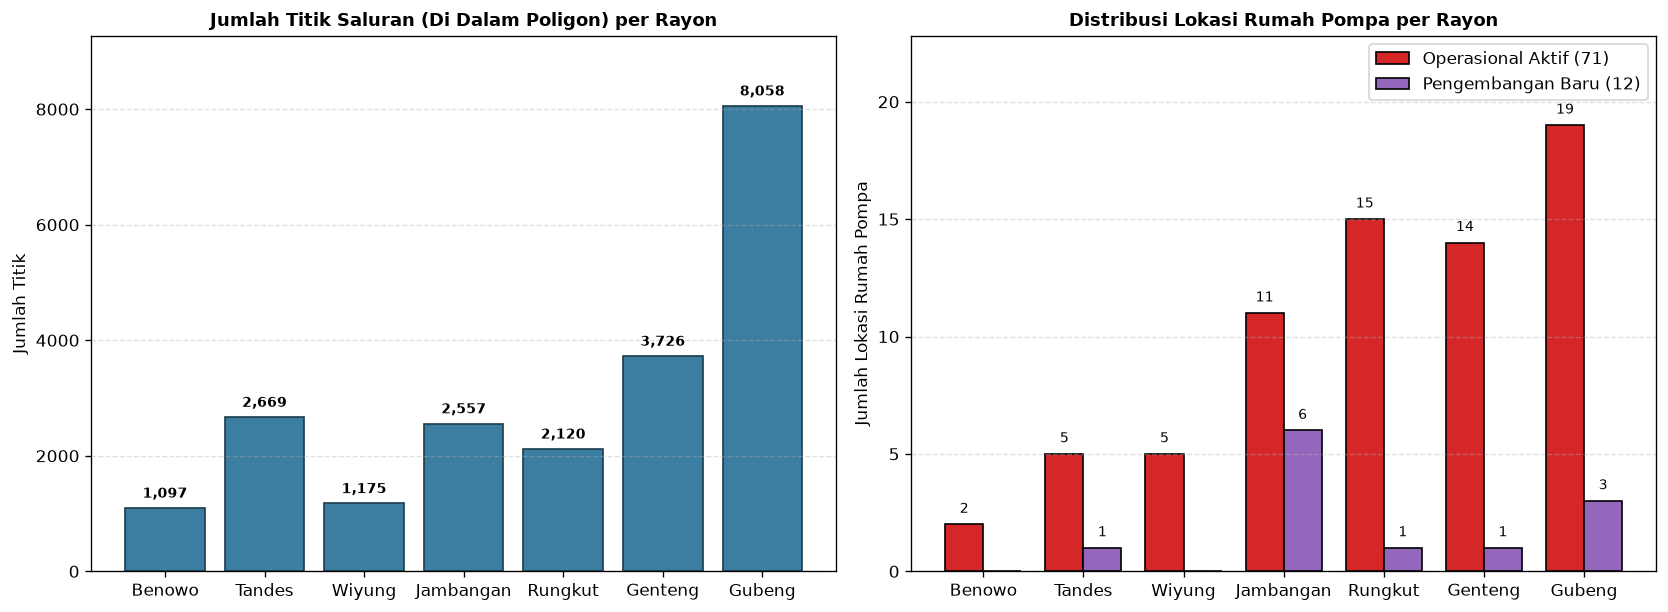

Gambar 3 disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\01_distribusi_deskriptif.png


In [9]:
# --- GAMBAR 3 & TABEL RINGKASAN PER RAYON (BAHAN BAB III) ---
urutan_rayon = gdf_rayon["nama_rayon"].tolist()

# Hitung ringkasan per rayon
pip_in_counts = pip_check["nama_rayon"].value_counts()
out_nearest_counts = df_outside["rayon_terdekat_hitung"].value_counts()
dup_extra_counts = df_dup_groups.groupby("rayon_pip")["baris_berlebih"].sum()
pompa_aktif_counts = gdf_pompa[gdf_pompa["status_fasilitas"] == "Operasional Aktif"]["rayon_pematusan"].value_counts()
pompa_kembang_counts = gdf_pompa[gdf_pompa["status_fasilitas"] == "Pengembangan Baru"]["rayon_pematusan"].value_counts()

summary_rows = []
for _, r in gdf_rayon.iterrows():
    rn = r["nama_rayon"]
    n_in = int(pip_in_counts.get(rn, 0))
    n_out = int(out_nearest_counts.get(rn, 0))
    n_dup_ex = int(dup_extra_counts.get(rn, 0))
    n_pa = int(pompa_aktif_counts.get(rn, 0))
    n_pk = int(pompa_kembang_counts.get(rn, 0))
    summary_rows.append({
        "id_rayon": r["id_rayon"],
        "nama_rayon": rn,
        "luas_km2": r["luas_km2"],
        "titik_dalam_poligon": n_in,
        "titik_luar_poligon_terdekat": n_out,
        "total_jika_gabung": n_in + n_out,
        "duplikat_koordinat_berlebih": n_dup_ex,
        "kepadatan_titik_per_km2": round(n_in / r["luas_km2"], 2),
        "pompa_aktif": n_pa,
        "pompa_pengembangan": n_pk,
        "total_pompa": n_pa + n_pk,
    })

df_ringkasan = pd.DataFrame(summary_rows)
display(df_ringkasan)

out_csv_ringkasan = TAB_DIR / "01_eda_ringkasan_per_rayon.csv"
df_ringkasan.to_csv(out_csv_ringkasan, index=False)
print(f"Tabel ringkasan per rayon disimpan ke: {out_csv_ringkasan}")

# Visualisasi grafik batang 2 panel
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Panel 1: Jumlah titik saluran dalam poligon per rayon
ax = axes[0]
short_names = [n.replace("Rayon ", "") for n in df_ringkasan["nama_rayon"]]
bars = ax.bar(short_names, df_ringkasan["titik_dalam_poligon"], color="#3B7EA1", edgecolor="#1B3B4B")
for b in bars:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width() / 2, h + 120, f"{int(h):,}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
ax.set_title("Jumlah Titik Saluran (Di Dalam Poligon) per Rayon", fontsize=11, fontweight="bold")
ax.set_ylabel("Jumlah Titik")
ax.set_ylim(0, df_ringkasan["titik_dalam_poligon"].max() * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Panel 2: Jumlah Rumah Pompa Aktif vs Pengembangan per Rayon
ax = axes[1]
x = np.arange(len(short_names))
w = 0.38
b1 = ax.bar(x - w/2, df_ringkasan["pompa_aktif"], width=w, label="Operasional Aktif (71)", color="#D62728", edgecolor="black")
b2 = ax.bar(x + w/2, df_ringkasan["pompa_pengembangan"], width=w, label="Pengembangan Baru (12)", color="#9467BD", edgecolor="black")
for b in list(b1) + list(b2):
    h = b.get_height()
    if h > 0:
        ax.text(b.get_x() + b.get_width() / 2, h + 0.35, f"{int(h)}", ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(short_names)
ax.set_title("Distribusi Lokasi Rumah Pompa per Rayon", fontsize=11, fontweight="bold")
ax.set_ylabel("Jumlah Lokasi Rumah Pompa")
ax.set_ylim(0, df_ringkasan["pompa_aktif"].max() * 1.2)
ax.legend(frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.4)

fig_path_3 = FIG_DIR / "01_distribusi_deskriptif.png"
plt.tight_layout()
plt.savefig(fig_path_3, dpi=200, bbox_inches="tight")
plt.show()
print(f"Gambar 3 disimpan ke: {fig_path_3}")